In [1]:
get_ipython().run_line_magic('pip', 'install matplotlib seaborn pandas numpy')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("DataSets/FantasyData.csv")

# Missing counts mean "did not do that", so 0 is fine (NOT for rate columns like Ctch% or Y/Tgt)
count_cols = ['G', 'GS', 'RushAtt', 'RushYds', 'RushTD', 'Rush1D',
              'Cmp', 'PassAtt', 'PassYds', 'PassTD', 'Int', 'Pass1D',
              'Tgt', 'Rec', 'ReceiveYds', 'ReceiveTD', 'Receive1D']
df[count_cols] = df[count_cols].fillna(0)

# Only the four fantasy-relevant positions
df = df[df['Pos'].isin(['QB', 'RB', 'WR', 'TE'])].copy()

# One row per player-season (traded players can have a combined row plus per-team rows)
before = len(df)
df = df.sort_values('G', ascending=False).drop_duplicates(['Player', 'year']).sort_index()
print(f"Dropped {before - len(df)} duplicate player-season rows; {len(df)} rows remain.")
print(df.groupby(['year', 'Pos']).size().unstack())


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Dropped 0 duplicate player-season rows; 1111 rows remain.
Pos   QB   RB   TE   WR
year                   
2024  78  133  117  222
2025  81  138  122  220


In [2]:
get_ipython().run_line_magic('pip', 'install matplotlib seaborn pandas numpy')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("DataSets/FantasyData.csv")

# Missing counts mean "did not do that", so 0 is fine (NOT for rate columns like Ctch% or Y/Tgt)
count_cols = ['G', 'GS', 'RushAtt', 'RushYds', 'RushTD', 'Rush1D',
              'Cmp', 'PassAtt', 'PassYds', 'PassTD', 'Int', 'Pass1D',
              'Tgt', 'Rec', 'ReceiveYds', 'ReceiveTD', 'Receive1D']
df[count_cols] = df[count_cols].fillna(0)

# Only the four fantasy-relevant positions
df = df[df['Pos'].isin(['QB', 'RB', 'WR', 'TE'])].copy()

# One row per player-season (traded players can have a combined row plus per-team rows)
before = len(df)
df = df.sort_values('G', ascending=False).drop_duplicates(['Player', 'year']).sort_index()
print(f"Dropped {before - len(df)} duplicate player-season rows; {len(df)} rows remain.")
print(df.groupby(['year', 'Pos']).size().unstack())


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Dropped 0 duplicate player-season rows; 1111 rows remain.
Pos   QB   RB   TE   WR
year                   
2024  78  133  117  222
2025  81  138  122  220


In [3]:
g0 = df['G'].replace(0, np.nan)
df['Plays'] = df['RushAtt'] + df['Rec'] + df['PassAtt']
df['PlaysPG'] = df['Plays'] / g0
df['TgtPG'] = df['Tgt'] / g0
df['RushAttPG'] = df['RushAtt'] / g0
df['PassAttPG'] = df['PassAtt'] / g0

MIN_PLAYS = {'QB': 200, 'RB': 100, 'WR': 40, 'TE': 30}
df['MinPlays'] = df['Pos'].map(MIN_PLAYS)
qual = df[df['Plays'] >= df['MinPlays']].copy()
print(f"{len(qual)} qualified player-seasons (of {len(df)})")

390 qualified player-seasons (of 1111)


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


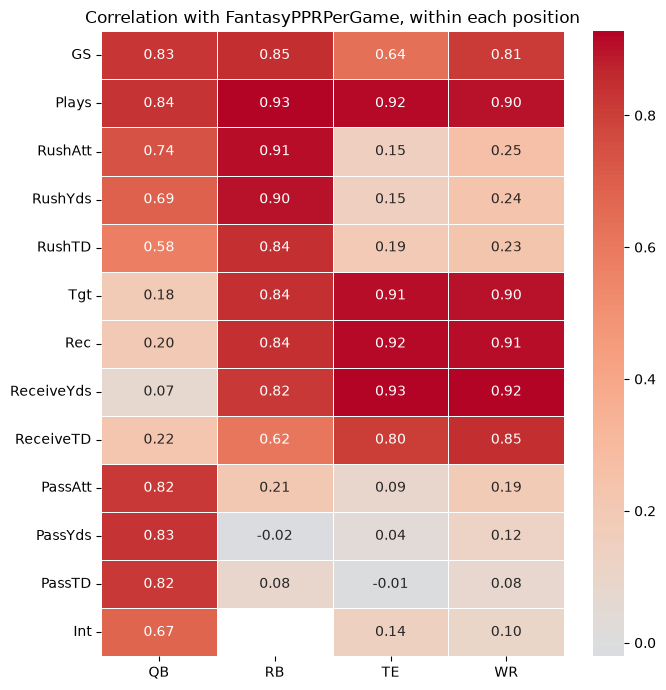

In [4]:
features = ['GS', 'Plays', 'RushAtt', 'RushYds', 'RushTD', 'Tgt', 'Rec', 'ReceiveYds', 'ReceiveTD',
            'PassAtt', 'PassYds', 'PassTD', 'Int']
by_pos = pd.DataFrame({
    pos: g[features].corrwith(g['FantasyPPRPerGame']) for pos, g in df.groupby('Pos')
})
plt.figure(figsize=(7, 7))
sns.heatmap(by_pos, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=.5)
plt.title('Correlation with FantasyPPRPerGame, within each position')
plt.tight_layout()
plt.show()

In [5]:
def cv_r2(X, y, k=5, reps=30, seed=0):
    X = np.asarray(X, float)
    if X.ndim == 1:
        X = X[:, None]
    y = np.asarray(y, float)
    n = len(y)
    rng = np.random.default_rng(seed)
    scores = []
    for _ in range(reps):
        idx = rng.permutation(n)
        pred = np.empty(n)
        for f in np.array_split(idx, k):
            tr = np.setdiff1d(idx, f)
            A = np.column_stack([np.ones(len(tr)), X[tr]])
            beta = np.linalg.lstsq(A, y[tr], rcond=None)[0]
            pred[f] = np.column_stack([np.ones(len(f)), X[f]]) @ beta
        scores.append(1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum())
    return float(np.mean(scores))


years = sorted(df['year'].unique())
y0, y1 = years[0], years[-1]
pos_map = df.drop_duplicates('Player').set_index('Player')['Pos']

vals = ['PlaysPG', 'TgtPG', 'RushAttPG', 'PassAttPG', 'FantasyPPRPerGame']
nxt = qual.pivot_table(index='Player', columns='year', values=vals).dropna()
nxt['Pos'] = pos_map.reindex(nxt.index)

rows = []
for pos, g in nxt.groupby('Pos'):
    if len(g) < 20:
        continue
    y = g[('FantasyPPRPerGame', y1)]
    last_ppr = g[('FantasyPPRPerGame', y0)]
    usage = np.column_stack([g[(c, y0)] for c in ['PlaysPG', 'TgtPG', 'RushAttPG', 'PassAttPG']])
    rows.append({
        'Pos': pos,
        'n': len(g),
        'last PPR/G only': cv_r2(last_ppr, y),
        'last usage only': cv_r2(usage, y),
        'last PPR/G + usage': cv_r2(np.column_stack([last_ppr, usage]), y),
    })
print(f"Out-of-sample R^2 predicting {y1} PPR/G from {y0} features")
pd.DataFrame(rows).set_index('Pos').round(3)

Out-of-sample R^2 predicting 2025 PPR/G from 2024 features


,n,last PPR/G only,last usage only,last PPR/G + usage
Pos,,,,
QB,29,0.016,-0.009,-0.054
RB,36,0.350,0.039,0.154
TE,28,-0.105,-6.486,-5.696
WR,44,0.345,0.263,0.244


In [6]:
usage_cols = {
    'QB': ['PassAttPG', 'RushAttPG'],
    'RB': ['RushAttPG', 'TgtPG'],
    'WR': ['TgtPG'],
    'TE': ['TgtPG'],
}

rows = []
for pos, g in nxt.groupby('Pos'):
    if len(g) < 20:
        continue
    y = g[('FantasyPPRPerGame', y1)]
    last_ppr = g[('FantasyPPRPerGame', y0)]
    usage = np.column_stack([g[(c, y0)] for c in usage_cols[pos]])
    rows.append({
        'Pos': pos,
        'n': len(g),
        'last PPR/G only': cv_r2(last_ppr, y),
        'last usage only': cv_r2(usage, y),
        'last PPR/G + usage': cv_r2(np.column_stack([last_ppr, usage]), y),
    })
pd.DataFrame(rows).set_index('Pos').round(3)

,n,last PPR/G only,last usage only,last PPR/G + usage
Pos,,,,
QB,29,0.016,-0.034,-0.060
RB,36,0.350,0.108,0.227
TE,28,-0.105,-0.064,-0.200
WR,44,0.345,0.317,0.337


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/seaborn/regression.py:598: UserWarning: sharex is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/seaborn/regression.py:598: UserWarning: sharey is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


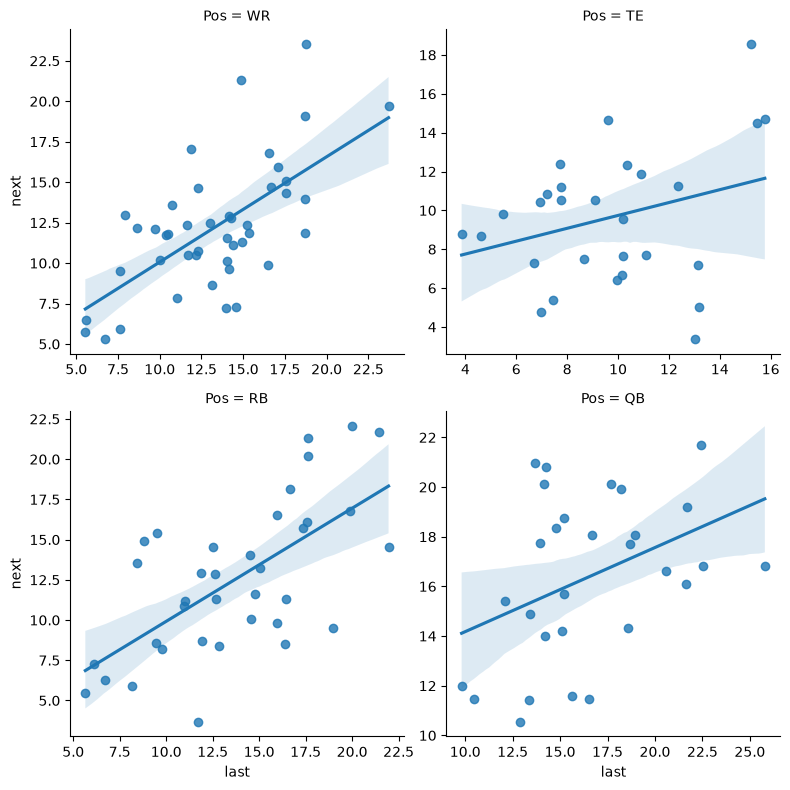

In [7]:
plot_df = pd.DataFrame({
    'last': nxt[('FantasyPPRPerGame', y0)],
    'next': nxt[('FantasyPPRPerGame', y1)],
    'Pos': nxt['Pos'],
})
sns.lmplot(data=plot_df, x='last', y='next', col='Pos', col_wrap=2, height=4, sharex=False, sharey=False)
plt.show()

In [8]:
age_tbl = (df.groupby(['Pos', 'Age'])['FantasyPPRPerGame']
             .agg(['mean', 'count'])
             .query('count >= 5')
             .round(2))
age_tbl

mean  count
Pos Age               
QB  22.0  13.58      5
    23.0  10.47      9
    24.0  10.07     15
    25.0   7.80     20
    26.0  10.58     19
    27.0  11.57     16
    28.0  11.35     12
    29.0   8.58     15
    30.0   8.45      9
    31.0  11.04      7
    32.0   6.84      6
    33.0  11.12      6
RB  21.0   3.13      9
    22.0   6.87     21
    23.0   7.05     31
    24.0   6.08     35
    25.0   6.03     50
    26.0   6.37     45
    27.0   6.90     27
    28.0   6.31     17
    29.0   6.80     17
    30.0   8.92     10
TE  22.0   4.89      9
    23.0   4.55     15
    24.0   3.18     31
    25.0   4.00     39
    26.0   3.41     37
    27.0   2.81     23
    28.0   3.74     18
    29.0   5.57     17
    30.0   4.34     16
    31.0   4.10     14
    32.0   4.47      7
WR  21.0   9.03      5
    22.0   7.29     23
    23.0   5.75     61
    24.0   5.91     70
    25.0   6.76     61
    26.0   5.19     45
    27.0   4.63     46
    28.0   5.55     38
    29.0   4.49     31
    30.0   5.07     23
    31.0   6.65     17
    32.0   6.75     16

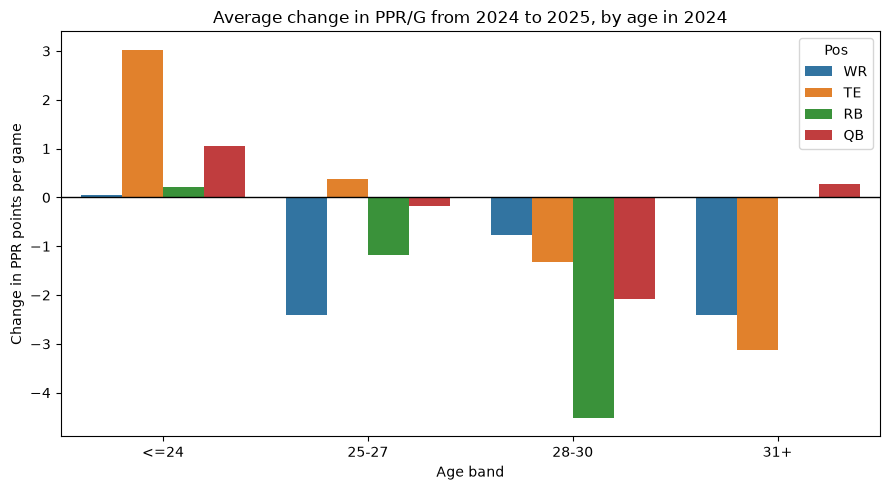

Age band,<=24,25-27,28-30,31+
Pos,,,,
QB,7,11,5,6
RB,12,19,5,0
TE,6,10,8,4
WR,21,14,4,5


In [9]:
age0 = qual[qual['year'] == y0].set_index('Player')['Age']

change = pd.DataFrame({
    'Pos': nxt['Pos'],
    'Age': age0.reindex(nxt.index),
    'PPR/G change': nxt[('FantasyPPRPerGame', y1)] - nxt[('FantasyPPRPerGame', y0)],
}).dropna()

bands = [0, 24, 27, 30, 50]
labels = ['<=24', '25-27', '28-30', '31+']
change['Age band'] = pd.cut(change['Age'], bins=bands, labels=labels)

plt.figure(figsize=(9, 5))
sns.barplot(data=change, x='Age band', y='PPR/G change', hue='Pos', errorbar=None)
plt.axhline(0, color='black', linewidth=1)
plt.title(f'Average change in PPR/G from {y0} to {y1}, by age in {y0}')
plt.ylabel('Change in PPR points per game')
plt.tight_layout()
plt.show()

# Sample sizes behind each bar
change.groupby(['Pos', 'Age band'], observed=True).size().unstack(fill_value=0)

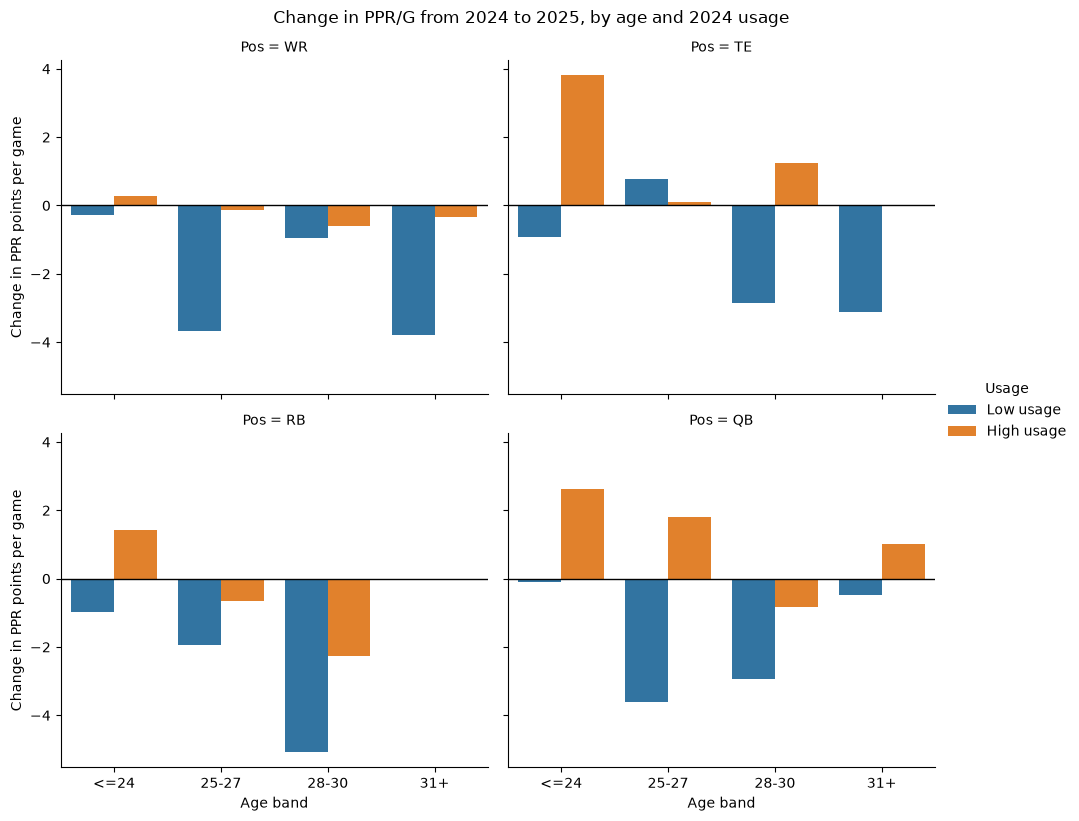

Age band        <=24  25-27  28-30  31+
Pos Usage                              
QB  Low usage      3      7      2    3
    High usage     4      4      3    3
RB  Low usage      6     11      1    0
    High usage     6      8      4    0
TE  Low usage      5      6      3    0
    High usage     1      4      5    4
WR  Low usage     13      5      2    2
    High usage     8      9      2    3

In [10]:
age0 = qual[qual['year'] == y0].set_index('Player')['Age']

change = pd.DataFrame({
    'Pos': nxt['Pos'],
    'Age': age0.reindex(nxt.index),
    'PlaysPG': nxt[('PlaysPG', y0)],
    'PPR/G change': nxt[('FantasyPPRPerGame', y1)] - nxt[('FantasyPPRPerGame', y0)],
}).dropna()

# High vs low usage = above/below the median plays per game within the same position
change['Usage'] = (change.groupby('Pos')['PlaysPG']
                         .transform(lambda s: pd.qcut(s.rank(method='first'), 2, labels=['Low usage', 'High usage'])))

bands = [0, 24, 27, 30, 50]
labels = ['<=24', '25-27', '28-30', '31+']
change['Age band'] = pd.cut(change['Age'], bins=bands, labels=labels)

g = sns.catplot(data=change, x='Age band', y='PPR/G change', hue='Usage', col='Pos',
                kind='bar', errorbar=None, col_wrap=2, height=4, aspect=1.2,
                hue_order=['Low usage', 'High usage'])
for ax in g.axes.flat:
    ax.axhline(0, color='black', linewidth=1)
g.set_axis_labels('Age band', 'Change in PPR points per game')
g.figure.suptitle(f'Change in PPR/G from {y0} to {y1}, by age and {y0} usage', y=1.02)
plt.show()

# Sample sizes behind each bar
change.groupby(['Pos', 'Usage', 'Age band'], observed=True).size().unstack(fill_value=0)

In [11]:
rb = qual[qual['Pos'] == 'RB'].copy()
rb['YPC'] = rb['RushYds'] / rb['RushAtt'].replace(0, np.nan)
w = rb.pivot_table(index='Player', columns='year',
                   values=['RushAttPG', 'YPC', 'FantasyPPRPerGame']).dropna()
age_rb = rb[rb['year'] == y0].set_index('Player')['Age']

out = pd.DataFrame({
    'Age': age_rb.reindex(w.index),
    'Carries/G change': w[('RushAttPG', y1)] - w[('RushAttPG', y0)],
    'YPC change': w[('YPC', y1)] - w[('YPC', y0)],
    'PPR/G change': w[('FantasyPPRPerGame', y1)] - w[('FantasyPPRPerGame', y0)],
}).dropna()
out['Age band'] = pd.cut(out['Age'], bins=[0, 24, 27, 30, 50], labels=['<=24', '25-27', '28-30', '31+'])

out.groupby('Age band', observed=True).agg(
    n=('PPR/G change', 'size'),
    carries=('Carries/G change', 'mean'),
    ypc=('YPC change', 'mean'),
    ppr=('PPR/G change', 'mean'),
).round(2)

,n,carries,ypc,ppr
Age band,,,,
<=24,12,1.06,0.06,0.22
25-27,19,-1.24,-0.02,-1.19
28-30,5,-3.97,-0.12,-4.52


In [12]:
rows = []
for pos, g in nxt.groupby('Pos'):
    rows.append({
        'Pos': pos,
        'n': len(g),
        'PlaysPG persistence': g[('PlaysPG', y0)].corr(g[('PlaysPG', y1)]),
        'PPR/G persistence': g[('FantasyPPRPerGame', y0)].corr(g[('FantasyPPRPerGame', y1)]),
    })
pd.DataFrame(rows).set_index('Pos').round(2)

,n,PlaysPG persistence,PPR/G persistence
Pos,,,
QB,29,0.30,0.40
RB,36,0.60,0.65
TE,28,0.48,0.30
WR,44,0.70,0.64


In [13]:
# Create groups DataFrame from existing notebook data
groups = pd.DataFrame({
    'Pos': nxt['Pos'],
    'last': nxt[('FantasyPPRPerGame', y0)],
    'next': nxt[('FantasyPPRPerGame', y1)]
}).dropna()

In [14]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

all_clusters = []

for pos in ['QB', 'RB', 'WR', 'TE']:

    # Filter to one position
    subset = groups[groups['Pos'] == pos].copy()

    # Previous and next season fantasy points per game
    X = subset[['last', 'next']]

    # Standardize within each position
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Run K-means independently
    kmeans = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=10
    )

    subset['Cluster'] = kmeans.fit_predict(X_scaled)

    # Calculate cluster centers in original units
    centers = scaler.inverse_transform(kmeans.cluster_centers_)

    # Store results
    all_clusters.append(subset)

    print(f"\n{pos} Cluster Centers:")
    print(pd.DataFrame(
        centers,
        columns=['last', 'next']
    ).round(2))

# Combine all positions
clustered_df = pd.concat(all_clusters)

print("\nTotal clustered players:", len(clustered_df))


QB Cluster Centers:
    last   next
0  13.12  11.42
1  15.40  19.43
2  14.77  14.75
3  21.53  17.88

RB Cluster Centers:
    last   next
0  14.92  10.58
1  18.62  18.30
2   8.22   6.47
3  10.71  13.29

WR Cluster Centers:
    last   next
0  14.40  10.73
1  18.02  17.45
2  10.49  12.66
3   7.35   6.80

TE Cluster Centers:
    last   next
0  11.54   6.29
1   6.24   7.47
2  15.49  15.93
3   9.08  11.42

Total clustered players: 137


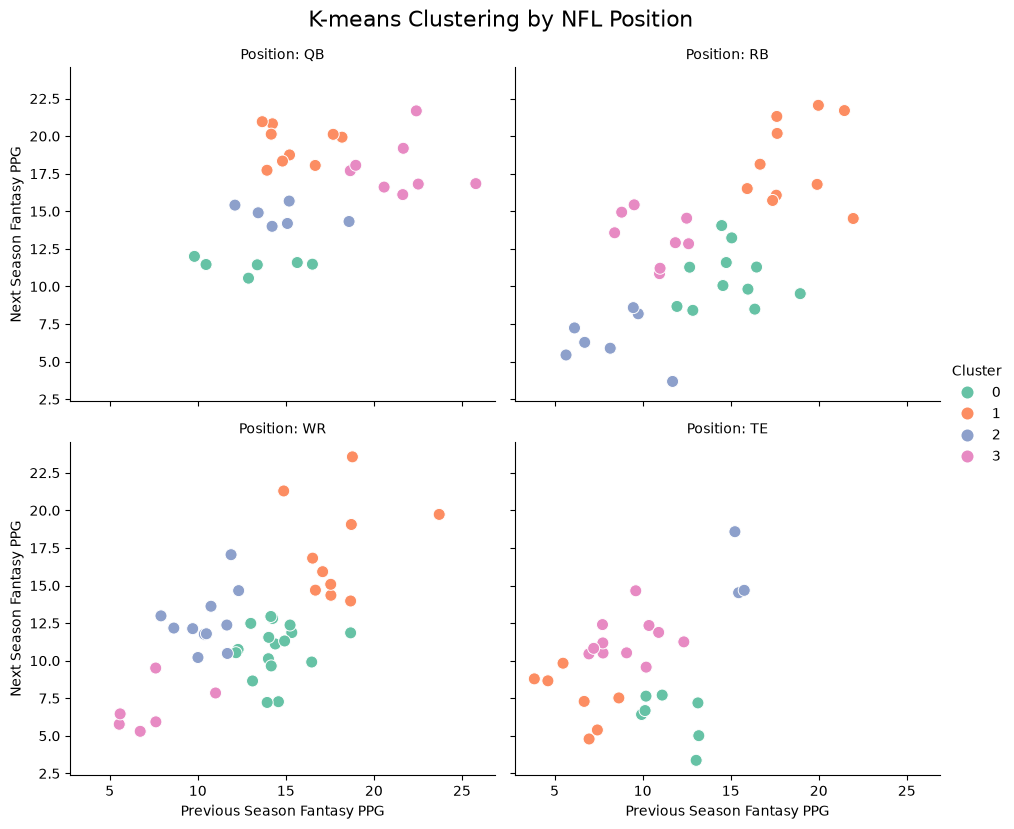

In [15]:
g = sns.relplot(
    data=clustered_df,
    x='last',
    y='next',
    hue='Cluster',
    col='Pos',
    col_wrap=2,
    palette='Set2',
    height=4,
    aspect=1.2,
    s=75
)

g.set_axis_labels(
    'Previous Season Fantasy PPG',
    'Next Season Fantasy PPG'
)

g.set_titles('Position: {col_name}')

g.fig.suptitle(
    'K-means Clustering by NFL Position',
    y=1.03,
    fontsize=16
)

plt.show()

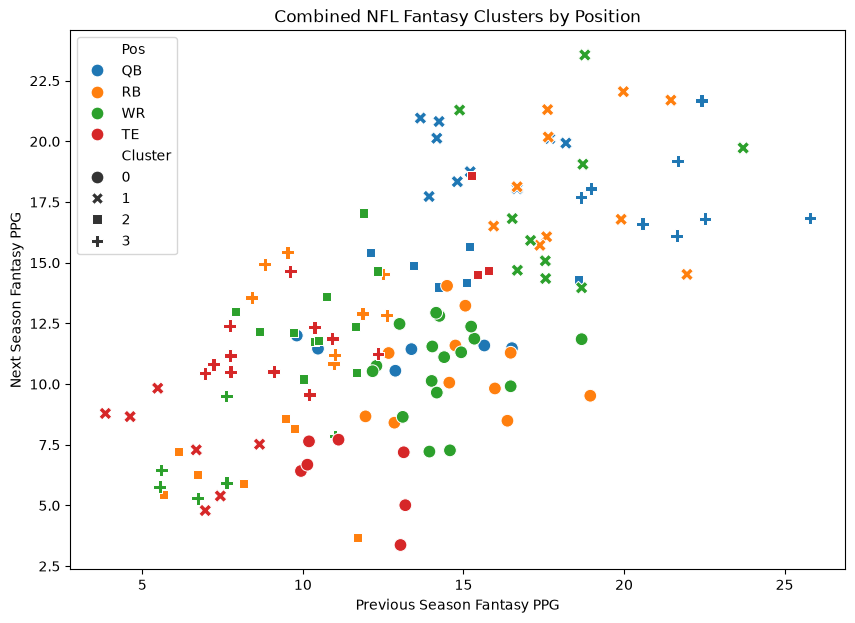

In [16]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=clustered_df,
    x='last',
    y='next',
    hue='Pos',
    style='Cluster',
    s=85
)

plt.xlabel('Previous Season Fantasy PPG')
plt.ylabel('Next Season Fantasy PPG')
plt.title('Combined NFL Fantasy Clusters by Position')

plt.show()

In [18]:
# CLUSTER SUMMARY STATISTICS

# Calculate position-specific median performance
position_medians = (
    clustered_df.groupby('Pos')[['last', 'next']]
    .median()
    .rename(columns={
        'last': 'Position_Median_Last',
        'next': 'Position_Median_Next'
    })
    .reset_index()
)

# Calculate cluster means and assign labels
cluster_summary = (
    clustered_df
    .groupby(['Pos', 'Cluster'])
    .agg(
        Players=('last', 'size'),
        Avg_Last=('last', 'mean'),
        Avg_Next=('next', 'mean')
    )
    .reset_index()
    .merge(position_medians, on='Pos')
)

cluster_summary['Last_Level'] = np.where(
    cluster_summary['Avg_Last'] >= cluster_summary['Position_Median_Last'],
    'High', 'Low'
)

cluster_summary['Next_Level'] = np.where(
    cluster_summary['Avg_Next'] >= cluster_summary['Position_Median_Next'],
    'High', 'Low'
)

cluster_summary['Label'] = (
    cluster_summary['Last_Level'] + ' → ' +
    cluster_summary['Next_Level']
)

# Add labels to individual players
clustered_df = clustered_df.drop(
    columns=['Label'], errors='ignore'
).merge(
    cluster_summary[['Pos', 'Cluster', 'Label']],
    on=['Pos', 'Cluster'],
    how='left'
)

# Calculate performance changes
clustered_df['Change'] = (
    clustered_df['next'] - clustered_df['last']
)

clustered_df['Pct_Change'] = np.where(
    clustered_df['last'] > 0,
    clustered_df['Change'] / clustered_df['last'] * 100,
    np.nan
)

# Complete summary statistics
cluster_summary = (
    clustered_df
    .groupby(['Pos', 'Cluster', 'Label'])
    .agg(
        Players=('last', 'size'),
        Avg_Last=('last', 'mean'),
        Avg_Next=('next', 'mean'),
        Median_Last=('last', 'median'),
        Median_Next=('next', 'median'),
        Std_Last=('last', 'std'),
        Std_Next=('next', 'std'),
        Avg_Change=('Change', 'mean'),
        Median_Change=('Change', 'median'),
        Avg_Pct_Change=('Pct_Change', 'mean')
    )
    .reset_index()
)

# Display results
print("CLUSTER SUMMARY STATISTICS")
display(cluster_summary.round(2))

# Check whether all four categories appear
for pos in ['QB', 'RB', 'WR', 'TE']:
    labels = cluster_summary.loc[
        cluster_summary['Pos'] == pos, 'Label'
    ]
    print(f"{pos}: {labels.nunique()} distinct performance groups")

CLUSTER SUMMARY STATISTICS


,Pos,Cluster,Label,Players,Avg_Last,Avg_Next,Median_Last,Median_Next,Std_Last,Std_Next,Avg_Change,Median_Change,Avg_Pct_Change
0,QB,0,Low → Low,6,13.12,11.42,13.13,11.47,2.68,0.47,-1.70,-2.14,-9.54
1,QB,1,High → High,9,15.40,19.43,14.81,19.93,1.70,1.22,4.03,3.54,27.52
2,QB,2,Low → Low,6,14.77,14.75,14.66,14.61,2.19,0.69,-0.02,0.13,1.82
3,QB,3,High → High,8,21.53,17.88,21.66,17.27,2.26,1.82,-3.66,-3.22,-16.19
4,RB,0,High → Low,11,14.92,10.58,14.75,10.06,2.01,1.89,-4.34,-4.44,-28.04
5,RB,1,High → High,10,18.62,18.30,17.63,17.46,2.06,2.78,-0.32,0.41,-0.86
6,RB,2,Low → Low,7,8.22,6.47,8.16,6.28,2.21,1.69,-1.75,-0.88,-16.25
7,RB,3,Low → High,8,10.71,13.29,10.98,13.24,1.63,1.67,2.58,1.54,27.63
8,TE,0,High → Low,7,11.54,6.29,11.11,6.68,1.53,1.58,-5.25,-3.52,-43.80
9,TE,1,Low → Low,7,6.24,7.47,6.68,7.52,1.68,1.84,1.23,0.61,33.22


QB: 2 distinct performance groups
RB: 4 distinct performance groups
WR: 4 distinct performance groups
TE: 4 distinct performance groups


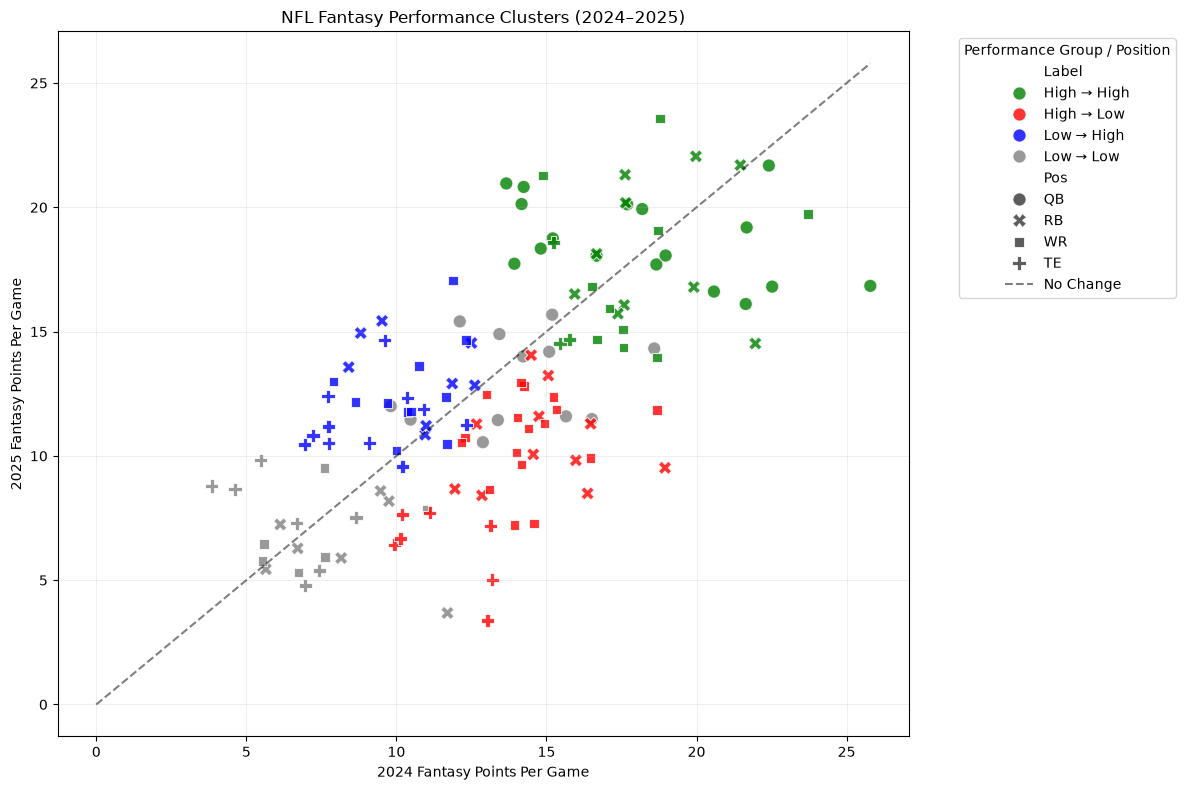

In [19]:
# COMBINED K-MEANS CLUSTER PLOT

plt.figure(figsize=(12, 8))

palette = {
    'High → High': 'green',
    'High → Low': 'red',
    'Low → High': 'blue',
    'Low → Low': 'gray'
}

sns.scatterplot(
    data=clustered_df,
    x='last',
    y='next',
    hue='Label',
    style='Pos',
    hue_order=[
        'High → High',
        'High → Low',
        'Low → High',
        'Low → Low'
    ],
    palette=palette,
    s=90,
    alpha=0.8
)

# Reference line: same fantasy PPG in both seasons
max_val = max(
    clustered_df['last'].max(),
    clustered_df['next'].max()
)

plt.plot(
    [0, max_val],
    [0, max_val],
    linestyle='--',
    color='black',
    alpha=0.5,
    label='No Change'
)

plt.xlabel('2024 Fantasy Points Per Game')
plt.ylabel('2025 Fantasy Points Per Game')
plt.title('NFL Fantasy Performance Clusters (2024–2025)')

plt.legend(
    title='Performance Group / Position',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


QB CLUSTER CHARACTERISTICS


,Age,GS,PassAttPG,RushAttPG,YardsPerPass
Label,,,,,
High → High,27.06,15.00,31.26,4.72,7.42
Low → Low,29.17,12.08,30.16,2.67,7.03


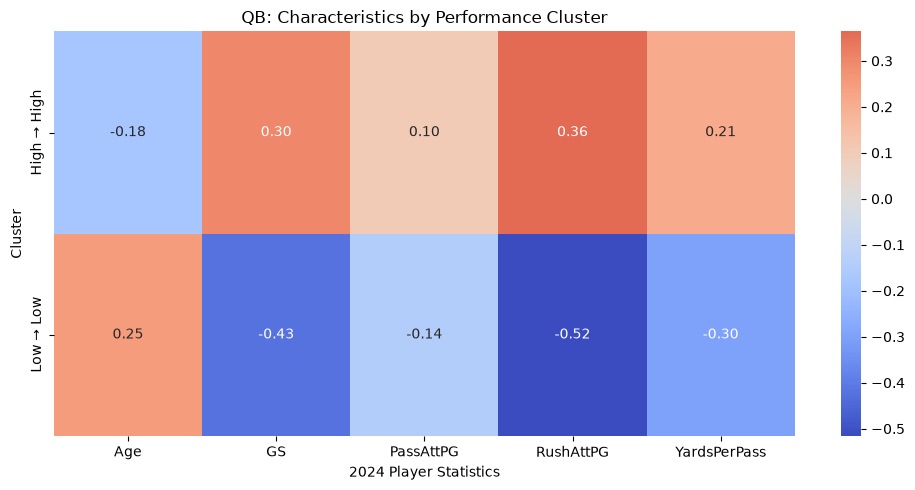


RB CLUSTER CHARACTERISTICS


,Age,GS,RushAttPG,TgtPG,YardsPerCarry
Label,,,,,
High → High,24.80,14.20,17.16,3.07,4.91
High → Low,26.09,12.73,14.18,3.77,4.33
Low → High,25.00,11.25,11.10,3.22,4.06
Low → Low,25.43,4.71,9.64,1.49,4.26


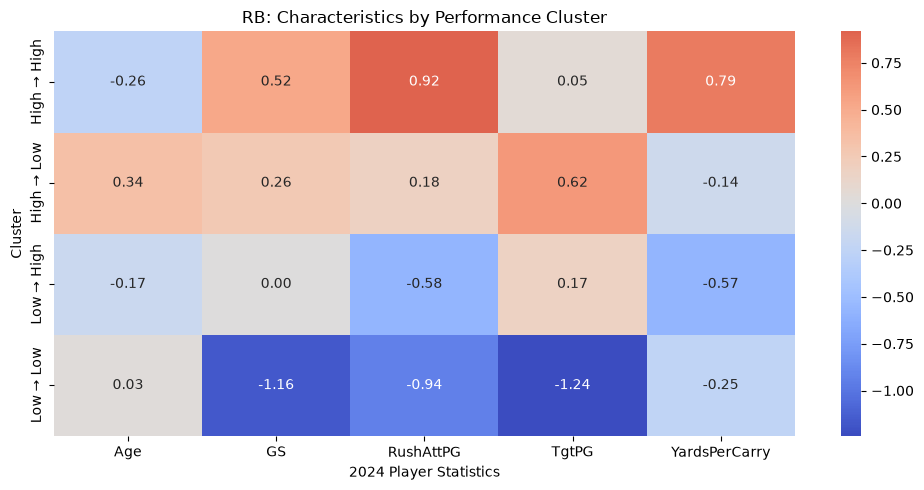


WR CLUSTER CHARACTERISTICS


,Age,GS,TgtPG,YardsPerTarget
Label,,,,
High → High,25.10,14.00,9.06,8.94
High → Low,26.18,12.94,7.66,8.52
Low → High,24.18,12.91,6.28,7.83
Low → Low,25.33,7.00,4.01,7.56


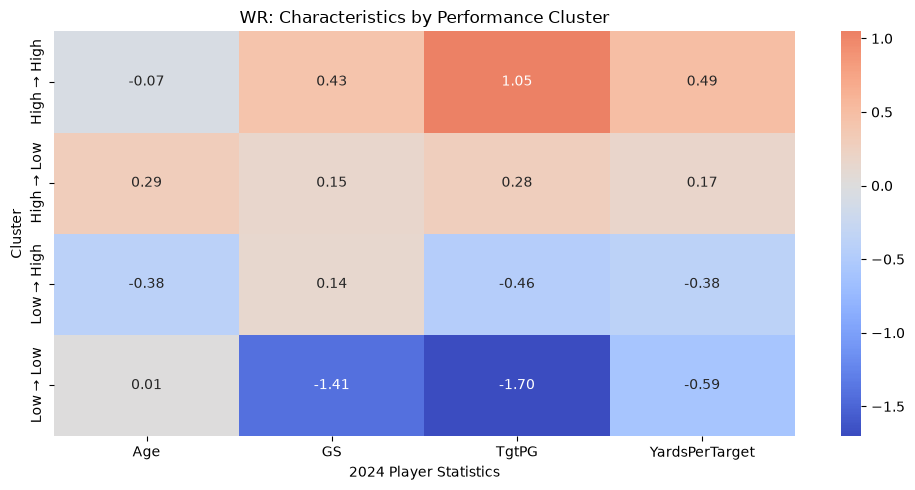


TE CLUSTER CHARACTERISTICS


,Age,GS,TgtPG,YardsPerTarget
Label,,,,
High → High,26.00,15.67,8.15,9.12
High → Low,28.71,10.29,5.89,7.13
Low → High,27.73,13.45,5.40,7.56
Low → Low,25.00,10.00,3.77,7.26


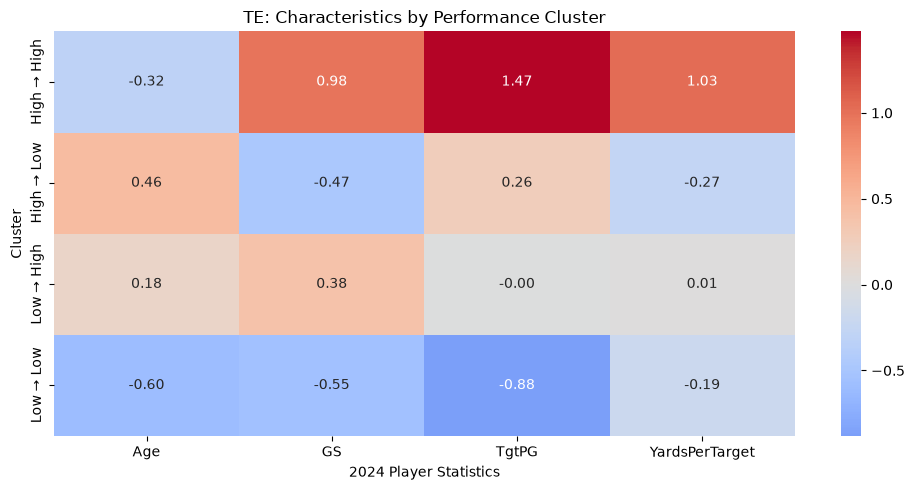

In [20]:
# 5. INVESTIGATING CLUSTER CHARACTERISTICS

# Calculate efficiency statistics
df['YardsPerCarry'] = df['RushYds'] / df['RushAtt'].replace(0, np.nan)
df['YardsPerTarget'] = df['ReceiveYds'] / df['Tgt'].replace(0, np.nan)
df['YardsPerPass'] = df['PassYds'] / df['PassAtt'].replace(0, np.nan)

# Statistics to investigate by position
position_features = {
    'QB': ['Age', 'GS', 'PassAttPG', 'RushAttPG', 'YardsPerPass'],
    'RB': ['Age', 'GS', 'RushAttPG', 'TgtPG', 'YardsPerCarry'],
    'WR': ['Age', 'GS', 'TgtPG', 'YardsPerTarget'],
    'TE': ['Age', 'GS', 'TgtPG', 'YardsPerTarget']
}

# Match clusters to player names using the original paired data
player_lookup = pd.DataFrame({
    'Player': nxt.index,
    'Pos': nxt['Pos'].to_numpy(),
    'last': nxt[('FantasyPPRPerGame', y0)].to_numpy(),
    'next': nxt[('FantasyPPRPerGame', y1)].to_numpy()
})

# Use a unique row ID to avoid ambiguous merges
player_lookup['PairID'] = np.arange(len(player_lookup))

groups_with_ids = groups.copy()
groups_with_ids['PairID'] = np.arange(len(groups_with_ids))

# Attach player IDs to clustered data
clustered_with_ids = clustered_df.merge(
    groups_with_ids[['Pos', 'last', 'next', 'PairID']],
    on=['Pos', 'last', 'next'],
    how='left',
    validate='many_to_one'
)

clustered_with_ids = clustered_with_ids.merge(
    player_lookup[['PairID', 'Player']],
    on='PairID',
    how='left',
    validate='many_to_one'
)

# Get 2024 player statistics
base = df[df['year'] == y0].copy()

analysis_df = clustered_with_ids.merge(
    base[['Player', 'Pos'] + list(set(
        sum(position_features.values(), [])
    ))],
    on=['Player', 'Pos'],
    how='left',
    validate='many_to_one'
)

# Compare cluster averages by position
for pos, features in position_features.items():

    subset = analysis_df[analysis_df['Pos'] == pos]

    summary = subset.groupby('Label')[features].mean()

    print(f"\n{pos} CLUSTER CHARACTERISTICS")
    display(summary.round(2))

    # Standardize statistics for easier comparison
    means = subset[features].mean()
    stds = subset[features].std().replace(0, np.nan)

    standardized = (summary - means) / stds

    plt.figure(figsize=(10, 5))

    sns.heatmap(
        standardized,
        annot=True,
        fmt='.2f',
        cmap='coolwarm',
        center=0
    )

    plt.title(f'{pos}: Characteristics by Performance Cluster')
    plt.xlabel('2024 Player Statistics')
    plt.ylabel('Cluster')
    plt.tight_layout()
    plt.show()